# Mini Project: Evaluating Clustering Before and After PCA

Dataset: Mice Protein Expression (UCI)

1080 samples and 77 protein features.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

df = pd.read_excel("Data_Cortex_Nuclear.xls")
df.head()

,MouseID,DYRK1A_N,ITSN1_N,BDNF_N,NR1_N,NR2A_N,pAKT_N,pBRAF_N,pCAMKII_N,pCREB_N,...,pCFOS_N,SYP_N,H3AcK18_N,EGR1_N,H3MeK4_N,CaNA_N,Genotype,Treatment,Behavior,class
0,309_1,0.503644,0.747193,0.430175,2.816329,5.990152,0.218830,0.177565,2.373744,0.232224,...,0.108336,0.427099,0.114783,0.131790,0.128186,1.675652,Control,Memantine,C/S,c-CS-m
1,309_2,0.514617,0.689064,0.411770,2.789514,5.685038,0.211636,0.172817,2.292150,0.226972,...,0.104315,0.441581,0.111974,0.135103,0.131119,1.743610,Control,Memantine,C/S,c-CS-m
2,309_3,0.509183,0.730247,0.418309,2.687201,5.622059,0.209011,0.175722,2.283337,0.230247,...,0.106219,0.435777,0.111883,0.133362,0.127431,1.926427,Control,Memantine,C/S,c-CS-m
3,309_4,0.442107,0.617076,0.358626,2.466947,4.979503,0.222886,0.176463,2.152301,0.207004,...,0.111262,0.391691,0.130405,0.147444,0.146901,1.700563,Control,Memantine,C/S,c-CS-m
4,309_5,0.434940,0.617430,0.358802,2.365785,4.718679,0.213106,0.173627,2.134014,0.192158,...,0.110694,0.434154,0.118481,0.140314,0.148380,1.839730,Control,Memantine,C/S,c-CS-m


# Step 1: Preprocess Data

Remove the label columns, we only use the 77 protein features.

In [2]:
X = df.drop(columns=["MouseID", "Genotype", "Treatment", "Behavior", "class"])
print(X.shape)

(1080, 77)


Check for duplicate rows.

In [3]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


There are no duplicates, so nothing to remove.

Check missing values and their percentage.

In [4]:
print("Missing values:", X.isnull().sum().sum())
print("Missing %:", X.isnull().sum().sum() / X.size * 100)

Missing values: 1396
Missing %: 1.6786916786916788


In [5]:
# missing % for each column
missing_percent = X.isnull().sum() / len(X) * 100
missing_percent[missing_percent > 0].sort_values(ascending=False).head(10)

BCL2_N        26.388889
H3MeK4_N      25.000000
BAD_N         19.722222
EGR1_N        19.444444
H3AcK18_N     16.666667
pCFOS_N        6.944444
ELK_N          1.666667
Bcatenin_N     1.666667
MEK_N          0.648148
ITSN1_N        0.277778
dtype: float64

Only 1.68% of the data is missing, and the highest column (BCL2_N) is 26%.

No column is above 50%, so we don't drop any column. We fill the missing values with the median.

In [6]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy="median")
X_filled = imputer.fit_transform(X)

print("Missing values after:", np.isnan(X_filled).sum())

Missing values after: 0


Scale the data using StandardScaler.

In [7]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_filled)

# Step 2: Clustering Before PCA

Use the Elbow Method to choose k.

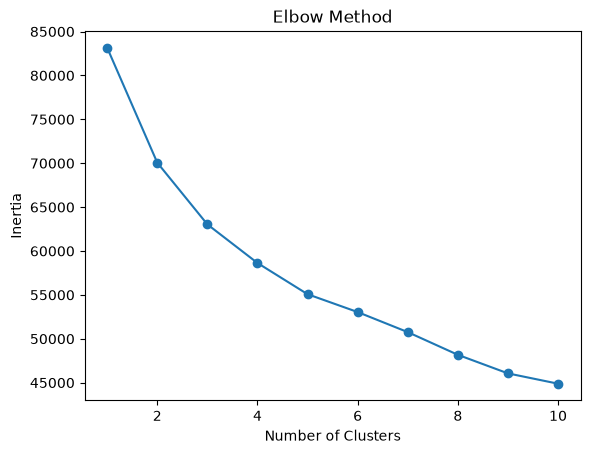

In [8]:
from sklearn.cluster import KMeans

inertia = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

There is no clear elbow, the inertia keeps going down slowly.

The dataset has 8 classes, so we use k = 8.

| Class | Genotype | Behavior | Treatment | Description | Samples |
|---|---|---|---|---|---|
| c-CS-m | Control | Context-Shock | Memantine | Normal, stimulated to learn, memantine | 150 |
| c-CS-s | Control | Context-Shock | Saline | Normal, stimulated to learn, saline | 135 |
| c-SC-m | Control | Shock-Context | Memantine | Normal, not stimulated to learn, memantine | 150 |
| c-SC-s | Control | Shock-Context | Saline | Normal, not stimulated to learn, saline | 135 |
| t-CS-m | Trisomy | Context-Shock | Memantine | Down syndrome, stimulated to learn, memantine | 135 |
| t-CS-s | Trisomy | Context-Shock | Saline | Down syndrome, stimulated to learn, saline | 105 |
| t-SC-m | Trisomy | Shock-Context | Memantine | Down syndrome, not stimulated to learn, memantine | 135 |
| t-SC-s | Trisomy | Shock-Context | Saline | Down syndrome, not stimulated to learn, saline | 135 |


In [9]:
from sklearn.metrics import silhouette_score

kmeans = KMeans(n_clusters=8, random_state=42)
clusters_before = kmeans.fit_predict(X_scaled)

score_before = silhouette_score(X_scaled, clusters_before)
print("Silhouette score before PCA:", score_before)

Silhouette score before PCA: 0.12252731329550838


# Step 3: Apply PCA

Reduce the data to 2 components.

In [10]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print(X_pca.shape)
print("Explained variance:", pca.explained_variance_ratio_)
print("Total:", pca.explained_variance_ratio_.sum())

(1080, 2)
Explained variance: [0.25349292 0.1691183 ]
Total: 0.42261122151089264


# Step 4: Clustering After PCA

In [11]:
kmeans_pca = KMeans(n_clusters=8, random_state=42)
clusters_after = kmeans_pca.fit_predict(X_pca)

score_after = silhouette_score(X_pca, clusters_after)
print("Silhouette score after PCA:", score_after)

Silhouette score after PCA: 0.34520483376003136


# Step 5: Visualization

Compare the clusters before and after PCA (both plotted on PC1 and PC2).

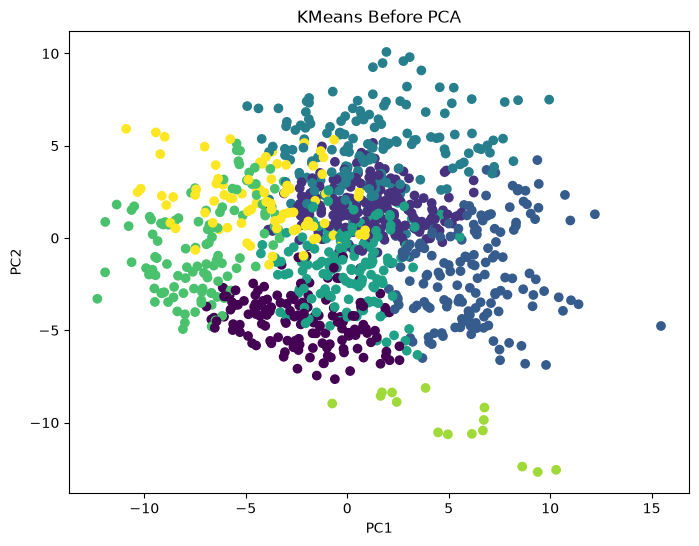

In [12]:
plt.figure(figsize=(8,6))
plt.scatter(X_pca[:,0], X_pca[:,1], c=clusters_before, cmap="viridis")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("KMeans Before PCA")
plt.show()

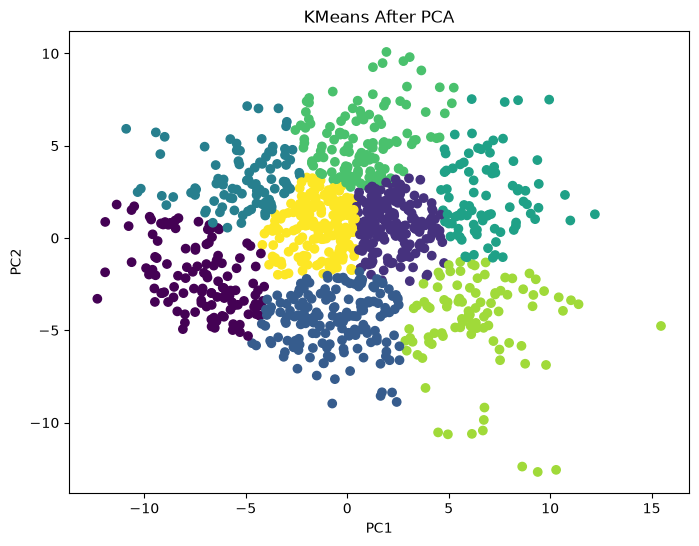

In [13]:
plt.figure(figsize=(8,6))
plt.scatter(X_pca[:,0], X_pca[:,1], c=clusters_after, cmap="viridis")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("KMeans After PCA")
plt.show()

In [14]:
print("Silhouette before PCA:", score_before)
print("Silhouette after PCA:", score_after)

Silhouette before PCA: 0.12252731329550838
Silhouette after PCA: 0.34520483376003136


# Step 6: Analysis

**How did PCA affect clustering results?**

The silhouette score went up from 0.12 to 0.35, so the clusters are more separated after PCA.

**Did visualization become clearer?**

Yes. After PCA the clusters are clean groups on the plot. Before PCA the clusters are mixed together when we plot them in 2D.

**Did you lose important information?**

Yes. The 2 components keep only 42% of the variance, so 58% of the information is lost.

**Which approach is better and why?**

PCA is better for visualization and gives a higher silhouette score. But it keeps only 42% of the data, so the original data has more information. The higher score after PCA is partly because 2D data is easier to separate.

# Bonus 1: Different Number of PCA Components

In [15]:
for n in [2, 3, 5, 10, 20]:
    pca_n = PCA(n_components=n)
    X_n = pca_n.fit_transform(X_scaled)

    km = KMeans(n_clusters=8, random_state=42)
    labels_n = km.fit_predict(X_n)

    print(n, "components, silhouette:", silhouette_score(X_n, labels_n))

2 components, silhouette: 0.34520483376003136
3 components, silhouette: 0.267114581082081
5 components, silhouette: 0.1969400885368422
10 components, silhouette: 0.16895259936754783
20 components, silhouette: 0.13838616215115213


More components → lower silhouette score. 2 components give the best score, but they also keep the least information.

# Bonus 2: DBSCAN

Try different eps values on the PCA data.

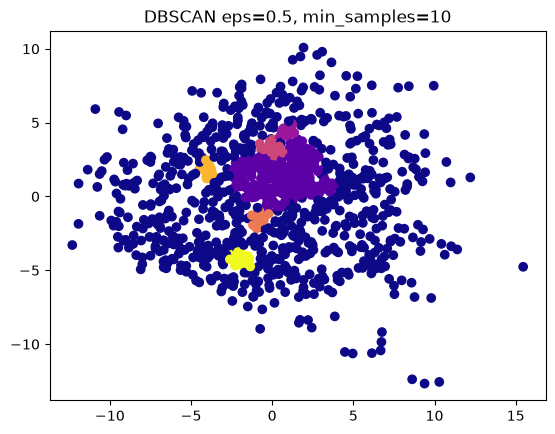

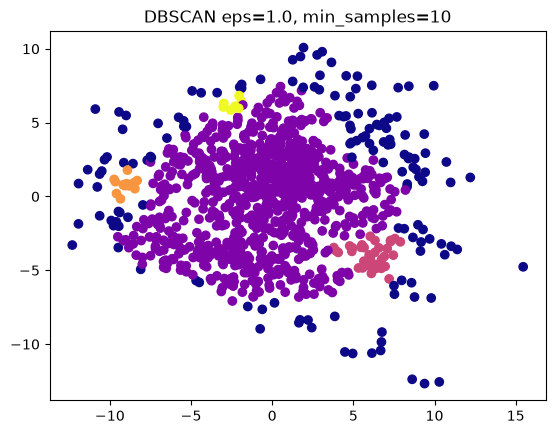

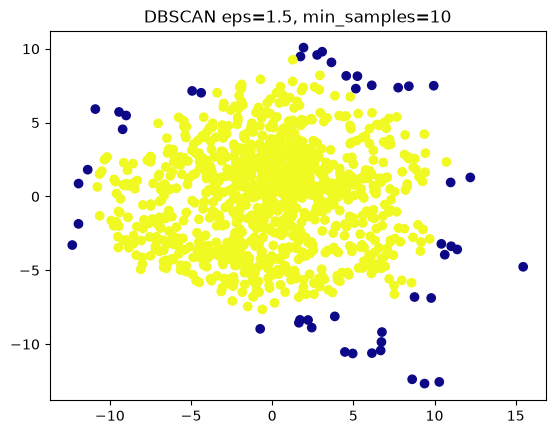

In [16]:
from sklearn.cluster import DBSCAN
for eps in [0.5, 1.0, 1.5]:
    db = DBSCAN(eps=eps, min_samples=10)
    clusters_db = db.fit_predict(X_pca)

    plt.scatter(X_pca[:,0], X_pca[:,1], c=clusters_db, cmap="plasma")
    plt.title(f"DBSCAN eps={eps}, min_samples=10")
    plt.show()

eps = 0.5 → a few small clusters and a lot of noise points. Too small.

eps = 1.0 → one big cluster and a few small ones.

eps = 1.5 → almost everything in one cluster. Too big.

DBSCAN does not work well here because the data is one big cloud with no clear dense groups. KMeans is better for this dataset.

# Final Summary

* No duplicates. Only 1.68% of the data was missing, so we filled it with the median and scaled the data.
* KMeans before PCA gave a low silhouette score (0.12).
* PCA with 2 components kept 42% of the variance.
* KMeans after PCA gave a higher silhouette score (0.35) and a clearer plot.
* PCA makes clustering faster and easier to see, but we lose some information.
* DBSCAN did not work well on this data.